# Sistema de Analisis Comercial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import os
import unicodedata

In [2]:
Ventas = pd.read_excel("/content/sample_data/01_ventas.xlsx")
Clientes = pd.read_excel("/content/sample_data/02_clientes.xlsx")
Productos = pd.read_excel("/content/sample_data/03_productos.xlsx")
Vendedores = pd.read_excel("/content/sample_data/04_vendedores.xlsx")
Sucursales = pd.read_excel("/content/sample_data/05_sucursales.xlsx")
Metas = pd.read_excel("/content/sample_data/06_metas.xlsx")

## Limpieza archivos

In [3]:
def limpiar_columnas(df):

    df.columns = [
        unicodedata.normalize('NFKD', col)
        .encode('ascii', errors='ignore')
        .decode('utf-8')
        .strip()

        for col in df.columns]
    return df
Ventas = limpiar_columnas(Ventas)
Clientes = limpiar_columnas(Clientes)
Productos = limpiar_columnas(Productos)
Vendedores = limpiar_columnas(Vendedores)
Sucursales = limpiar_columnas(Sucursales)
Metas = limpiar_columnas(Metas)

In [4]:
Metas = Metas.drop_duplicates()

fechas = pd.date_range(start= "2024-01-01", end = "2025-04-01", freq ="MS")    # Para recounstruir las columnas con un formato en especifico es necesario crear antes una lista con los valores que tomara la columna
sucursales = [f"SUC-{str(i).zfill(3)}" for i in range(1, 13)]
Metas['SucursalID'] = np.repeat(sucursales, len(fechas))
Metas['Fecha'] = fechas.tolist() * len(sucursales)

Metas['Meta_Ventas'] = pd.to_numeric(Metas['Meta_Ventas'], errors='coerce').astype('Int64')
Metas['Meta_Unidades'] = pd.to_numeric(Metas['Meta_Unidades'], errors='coerce').astype('Int64')

Metas.loc[Metas['Meta_Ventas'] <= 0, 'Meta_Ventas'] = np.nan
Metas.loc[Metas['Meta_Unidades'] <= 0, 'Meta_Unidades'] = np.nan

Metas['Meta_Ventas'] = Metas.groupby("SucursalID")['Meta_Ventas'].transform(lambda x:x.fillna(x.mean().round(0))).astype('Int64')
Metas['Meta_Unidades'] = Metas.groupby("SucursalID")['Meta_Unidades'].transform(lambda x:x.fillna(x.mean().round(0))).astype('Int64')

# Limpieza Vendedores
Vendedores['Nivel'] = Vendedores['Nivel'].fillna("Sin nivel")
Vendedores['VendedorID']=Vendedores['VendedorID'].astype(str).str.strip().str.upper()
Vendedores['VendedorID']=[f"VEND-{str(i).zfill(3)}" for i in range(1, len(Vendedores)+1)]

# Limpieza sucursales
Sucursales['Zona'] = Sucursales['Zona'].replace("###", "Sin zona")

# Limpieza productos
Productos = Productos.drop_duplicates()

Productos['ProductoID'] = [f"PROD-{str(i).zfill(4)}" for i in range(1, len(Productos)+1)]  # En este caso la reconstruccion no necesita de la construccion de una lista

categorias_validas = ['Moda', 'Hogar', 'Oficina', 'Tecnología', 'Deportes', 'Belleza', 'Sin dato', 'tecnología']
Productos.loc[~Productos['Categoria'].isin(categorias_validas),"Categoria"]=np.nan
for x in categorias_validas:
  categoria = Productos['Producto'].str.contains(x, case=False, na=False)
  Productos.loc[categoria & Productos['Categoria'].isna(), 'Categoria'] = x

for i in Productos.index:
  if pd.isna(Productos.loc[i, 'Producto']):
    producto = Productos.loc[i, 'Categoria']
    numero_correlativo = Productos.loc[i, 'ProductoID'].split('-')[1]
    numero_correlativo = int(numero_correlativo)
    Productos.loc[i, 'Producto'] = (f"{producto} producto {numero_correlativo}")

Productos["Producto"] = (Productos["Producto"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True).str.title())
Productos["Marca"] = (Productos["Marca"].astype(str).str.strip().str.title())
Productos['Marca'] = Productos['Marca'].fillna("Sin marca")
Productos['Marca'] = Productos['Marca'].replace("###","Sin marca")
Productos["Estado"] = (Productos["Estado"].astype(str).str.strip().str.title())
Productos['Estado'] = Productos['Estado'].fillna("Sin estado")
Productos['Estado'] = Productos['Estado'].replace("Sin dato","Sin estado")
Productos["Categoria"] = Productos["Categoria"].replace("Sin dato", "Sin categoria")

Productos['Costo_Unitario'] = pd.to_numeric(Productos['Costo_Unitario'], errors='coerce')
Productos['Precio_Lista'] = pd.to_numeric(Productos['Precio_Lista'], errors='coerce')
Productos.loc[Productos["Costo_Unitario"] >1000000,"Costo_Unitario"] = np.nan

relacion = (Productos['Costo_Unitario']/Productos['Precio_Lista']).mean()
Productos['Costo_Unitario'] = Productos['Costo_Unitario'].fillna(Productos['Precio_Lista'] * relacion).astype(int)
Productos['Precio_Lista'] = Productos['Precio_Lista'].fillna(Productos['Costo_Unitario']/relacion).astype(int)

# Limpieza clientes
Clientes = Clientes.drop_duplicates()

Clientes['ClienteID']=[f"CLI-{str(i).zfill(4)}" for i in range(1, len(Clientes)+1)]

Clientes['Segmento'] = Clientes['Segmento'].fillna("Sin segmento")
Clientes['Segmento'] = Clientes['Segmento'].replace("Sin dato", "Sin segmento")
Clientes['Estado'] = Clientes['Estado'].fillna("Sin estado")

Normalizacion_columnas = ["Cliente", "Pais", "Ciudad", "Estado", "Segmento"]

for columna in Normalizacion_columnas:
  Clientes[columna] = Clientes[columna].astype(str).str.strip().str.title()

# Limpieza ventas
Ventas = Ventas.drop_duplicates()
Ventas['VentaID'] = [f"VTA-{str(i).zfill(5)}" for i in range(1, len(Ventas)+1)]
Ventas['Fecha'] = pd.to_datetime(Ventas['Fecha'], errors="coerce")

Estadarizacion_columnasID = ["ClienteID", "VendedorID", "SucursalID", "ProductoID", "VentaID"]

for columna in Estadarizacion_columnasID:
  Ventas[columna] = Ventas[columna].astype(str).str.strip().str.upper()

Ventas["ClienteID"] = (Ventas["ClienteID"].str.extract(r"(\d+)")[0].str.zfill(4).radd("CLI-"))
Ventas['ClienteID'] = Ventas['ClienteID'].fillna("Sin cliente")
Ventas['ClienteID'] = Ventas['ClienteID'].replace("NO_EXISTE", "Sin cliente")

Ventas['ProductoID'] = (Ventas['ProductoID'].str.extract(r"(\d+)")[0].str.zfill(4).radd("PROD-"))
Ventas['ProductoID'] = Ventas['ProductoID'].fillna("Sin producto")
Ventas['ProductoID'] = Ventas['ProductoID'].replace("NO_EXISTE", "Sin producto")

Ventas['VendedorID'] = (Ventas['VendedorID'].str.extract(r"(\d+)")[0].str.zfill(3).radd("VEND-"))
Ventas['VendedorID'] = Ventas['VendedorID'].fillna("Sin vendedor")
Ventas['VendedorID'] = Ventas['VendedorID'].replace("NO_EXISTE", "Sin vendedor")

Ventas['SucursalID'] = (Ventas['SucursalID'].str.extract(r"(\d+)")[0].str.zfill(3).radd("SUC-"))
Ventas['SucursalID'] = Ventas['SucursalID'].fillna("Sin sucursal")
Ventas['SucursalID'] = Ventas['SucursalID'].replace("NO_EXISTE", "Sin sucursal")

Ventas['Canal'] = Ventas['Canal'].fillna("Sin canal")
Ventas['Canal'] = Ventas['Canal'].replace("Sin dato", "Sin canal")
Ventas['Canal'] = Ventas['Canal'].astype(str).str.strip().str.title()

Ventas['Metodo_Pago'] = Ventas['Metodo_Pago'].fillna("Sin metodo de pago")
Ventas['Metodo_Pago'] = Ventas['Metodo_Pago'].replace("Sin dato", "Sin metodo de pago")

Ventas['Cantidad'] = pd.to_numeric(Ventas['Cantidad'], errors='coerce')
Ventas.loc[(Ventas['Cantidad']<0) | (Ventas['Cantidad']>100000) , 'Cantidad'] = np.nan
Ventas['Cantidad'] = Ventas['Cantidad'].fillna(0)

Ventas = Ventas.merge(Productos[['ProductoID','Precio_Lista']], on= "ProductoID", how="left")
Ventas['Precio_Unitario'] = Ventas["Precio_Lista"]
Ventas.drop(columns="Precio_Lista",inplace=True)
Ventas['Precio_Unitario'] = Ventas['Precio_Unitario'].fillna(0)


Ventas['Descuento'] = pd.to_numeric(Ventas['Descuento'], errors='coerce')
Ventas['Descuento'] = Ventas['Descuento'].where(Ventas['Descuento'].between(0, 0.2),0)

Ventas['Total_Venta'] = Ventas['Precio_Unitario'] * Ventas['Cantidad'] * (1-Ventas['Descuento'])
Ventas['Total_Venta'] = Ventas['Total_Venta'].astype(int)

In [5]:
os.makedirs("datos_limpios", exist_ok=True)

Ventas.to_excel("/content/datos_limpios/Ventas_1.xlsx", index=False)
Clientes.to_excel("/content/datos_limpios/Clientes_2.xlsx", index=False)
Productos.to_excel("/content/datos_limpios/Productos_3.xlsx", index=False)
Vendedores.to_excel("/content/datos_limpios/Vendedores_4.xlsx", index=False)
Sucursales.to_excel("/content/datos_limpios/Sucursales_5.xlsx", index=False)
Metas.to_excel("/content/datos_limpios/Metas_6.xlsx", index=False)

## Carga y unificacion

In [6]:
Ventas1 = pd.read_excel("/content/datos_limpios/Ventas_1.xlsx")
Clientes2 = pd.read_excel("/content/datos_limpios/Clientes_2.xlsx")
Productos3 = pd.read_excel("/content/datos_limpios/Productos_3.xlsx")
Vendedores4 = pd.read_excel("/content/datos_limpios/Vendedores_4.xlsx")
Sucursales5 = pd.read_excel("/content/datos_limpios/Sucursales_5.xlsx")
Metas6 = pd.read_excel("/content/datos_limpios/Metas_6.xlsx")

In [7]:
Clientes2 = Clientes2.rename(columns={"Pais": "Pais_Cliente","Ciudad": "Ciudad_Cliente"})
Sucursales5 = Sucursales5.rename(columns={"Pais": "Pais_Sucursal","Ciudad": "Ciudad_Sucursal"})

Ventas1["Periodo"] = (Ventas1["Fecha"].dt.strftime("%Y-%m"))
Metas6["Periodo"] = (Metas6["Fecha"].dt.strftime("%Y-%m"))


Base_analitica_final = (
    Ventas1
    .merge(Clientes2[["ClienteID", "Cliente", "Pais_Cliente", "Ciudad_Cliente", "Segmento"]], on="ClienteID", how="left")
    .merge(Productos3[["ProductoID", "Producto", "Categoria", "Marca", "Estado", "Costo_Unitario"]], on="ProductoID", how="left")
    .merge(Vendedores4[["VendedorID", "Vendedor", "Nivel"]], on="VendedorID", how="left")
    .merge(Sucursales5[["SucursalID", "Sucursal", "Pais_Sucursal", "Ciudad_Sucursal", "Zona"]], on="SucursalID", how="left")
    .merge(Metas6[["SucursalID", "Periodo", "Meta_Ventas", "Meta_Unidades"]], on=["SucursalID", "Periodo"], how="left"))

In [8]:
Base_analitica_final.to_excel("/content/datos_limpios/Base_analitica_final.xlsx", index=False)

## Transformacion y creacion de metricas comerciales

In [9]:
Base_analitica = pd.read_excel("/content/datos_limpios/Base_analitica_final.xlsx")

In [10]:
# Ventas brutras y ventas netas
Base_analitica["Ventas_Brutas"] = Base_analitica["Precio_Unitario"] * Base_analitica["Cantidad"]
Base_analitica["Valor_Descuento"] = Base_analitica["Ventas_Brutas"] * Base_analitica['Descuento']
Base_analitica["Ventas_Netas"] = Base_analitica["Ventas_Brutas"] - Base_analitica["Valor_Descuento"]

# Costos, utilidad y margen
Base_analitica["Costos_Totales"] = Base_analitica["Costo_Unitario"] * Base_analitica["Cantidad"]
Base_analitica["Utilidad"] = Base_analitica["Ventas_Netas"] - Base_analitica["Costos_Totales"]
Base_analitica["Margen"] = Base_analitica["Utilidad"] / Base_analitica["Ventas_Netas"]

# Redondedo columnas
Columnas_redondeadas = ["Ventas_Brutas", "Valor_Descuento", "Ventas_Netas", "Costos_Totales", "Utilidad"]
Base_analitica[Columnas_redondeadas] = Base_analitica[Columnas_redondeadas].round(0)
Base_analitica["Margen"] = Base_analitica["Margen"].round(2)

In [11]:
Base_analitica.to_excel("/content/datos_limpios/Base_analitica_transformada.xlsx", index=False)

## Kpis principales

In [12]:
Base_Kpis = pd.read_excel("/content/datos_limpios/Base_analitica_transformada.xlsx")

def limpiar_columnas(df):

    df.columns = [
        unicodedata.normalize('NFKD', col)
        .encode('ascii', errors='ignore')
        .decode('utf-8')
        .strip()

        for col in df.columns]
    return df

Base_Kpis = limpiar_columnas(Base_Kpis)

# Ventas totales
Ventas_totales = Base_Kpis["Ventas_Netas"].sum()
# Utilidad Total
Utilidad_total = Base_Kpis["Utilidad"].sum()
# Margen promedio
Margen_promedio = Base_Kpis["Margen"].mean()
# Cantidad Vendida
Cantidad_vendida = Base_Kpis["Cantidad"].sum()
# Numero de ventas
Numero_ventas = Base_Kpis["VentaID"].nunique()
# Ticket promedio
Ticket_promedio = Ventas_totales / Numero_ventas
# Descuento promedio
Descuento_promedio = Base_Kpis["Descuento"].mean()

print("===================================")
print("KPIs PRINCIPALES")
print("===================================")
print(f"Ventas totales: {Ventas_totales: ,.0f}")
print(f"Utilidad total: {Utilidad_total: ,.0f}")
print(f"Margen promedio: {Margen_promedio: .2f}")
print(f"Cantidad vendida: {Cantidad_vendida: ,.0f}")
print(f"Numero de ventas: {Numero_ventas: ,.0f}")
print(f"Ticket promedio: {Ticket_promedio: ,.0f}")
print(f"Descuento promedio: {Descuento_promedio: .2f}")

KPIs PRINCIPALES
Ventas totales:  2,210,539,038
Utilidad total:  666,866,261
Margen promedio:  0.30
Cantidad vendida:  7,993
Numero de ventas:  1,800
Ticket promedio:  1,228,077
Descuento promedio:  0.08


## Tablas resumen

In [16]:
Base_Kpis1 = Base_Kpis.copy()
Base_Kpis1 = Base_Kpis1[
    (Base_Kpis1["Canal"] != "Sin Canal") &
    (Base_Kpis1["Categoria"] != "Sin categoria") &
    (Base_Kpis1["SucursalID"] != "Sin sucursal")]

# Ventas_mes
Ventas_mes = Base_Kpis1.groupby("Periodo")["Ventas_Netas"].sum().reset_index()
# Ventas categoria
Ventas_categoria = Base_Kpis1.groupby("Categoria")["Ventas_Netas"].sum().reset_index()
# Ventas pais
Ventas_pais = Base_Kpis1.groupby("Pais_Cliente")["Ventas_Netas"].sum().reset_index()
# Ventas canal
Ventas_canal = Base_Kpis1.groupby("Canal")["Ventas_Netas"].sum().reset_index()
# Top 10 productos
Top_productos = Base_Kpis1.groupby("Producto")["Ventas_Netas"].sum().reset_index().head(10)
# Top 10 vendedores
Top_vendedores = Base_Kpis1.groupby("Vendedor")["Ventas_Netas"].sum().reset_index().head(10)
# Utilidad sucursal
Utilidad_sucursal = Base_Kpis1.groupby("Sucursal")["Utilidad"].sum().reset_index()

## Cumplimiento de metas

In [21]:
Cumplimiento_metas = (Base_Kpis1.groupby(["SucursalID", "Periodo"])
.agg({"Ventas_Netas":"sum", "Cantidad": "sum", "Meta_Ventas": "first", "Meta_Unidades": "first"}).reset_index())

Cumplimiento_metas["Variacion_Absoluta_Ventas"] = (Cumplimiento_metas['Ventas_Netas']-Cumplimiento_metas['Meta_Ventas']).round(0).astype('Int64')
Cumplimiento_metas["Porcentaje_Cumplimiento_Ventas"] = ((Cumplimiento_metas['Ventas_Netas']/Cumplimiento_metas['Meta_Ventas'])*100).round(2)
Cumplimiento_metas["Variacion_Absoluta_Unidades"] = (Cumplimiento_metas['Cantidad']-Cumplimiento_metas['Meta_Unidades']).round(0).astype('Int64')
Cumplimiento_metas["Porcentaje_Cumplimiento_Unidades"] = ((Cumplimiento_metas['Cantidad']/Cumplimiento_metas['Meta_Unidades'])*100).round(2)

print("============= CUMPLIMIENTO METAS ============")
print(Cumplimiento_metas.head())

============= CUMPLIMIENTO METAS ============
  SucursalID  Periodo  Ventas_Netas  Cantidad  Meta_Ventas  Meta_Unidades  \
0    SUC-001  2024-01       7513021        33    6774353.0           38.0   
1    SUC-001  2024-02       3907617        13    3579350.0           14.0   
2    SUC-001  2024-03       5003057        21    5412798.0           23.0   
3    SUC-001  2024-04       2583054         7    2460269.0            7.0   
4    SUC-001  2024-05       2734420         7    3550319.0           10.0   

   Variacion_Absoluta_Ventas  Porcentaje_Cumplimiento_Ventas  \
0                     738668                          110.90   
1                     328267                          109.17   
2                    -409741                           92.43   
3                     122785                          104.99   
4                    -815899                           77.02   

   Variacion_Absoluta_Unidades  Porcentaje_Cumplimiento_Unidades  
0                           -5         

## Visualizaciones

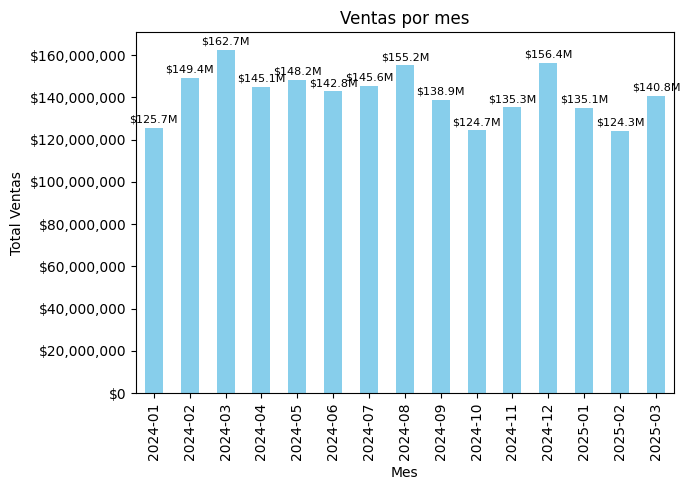

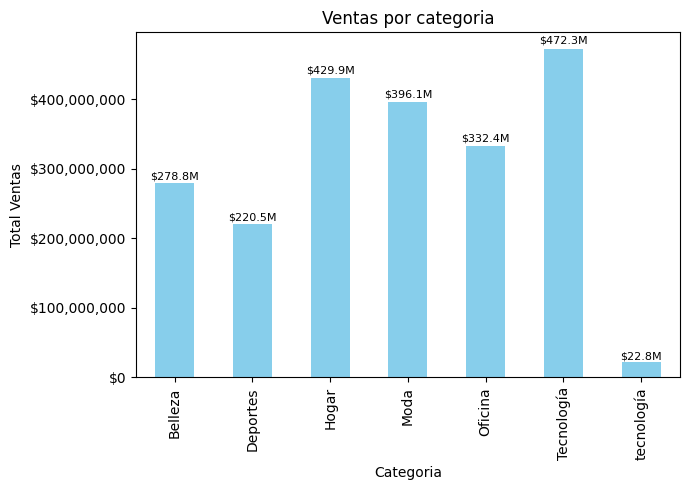

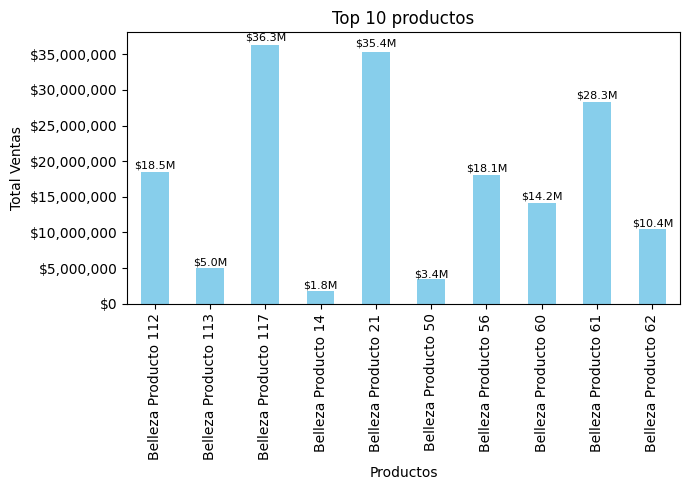

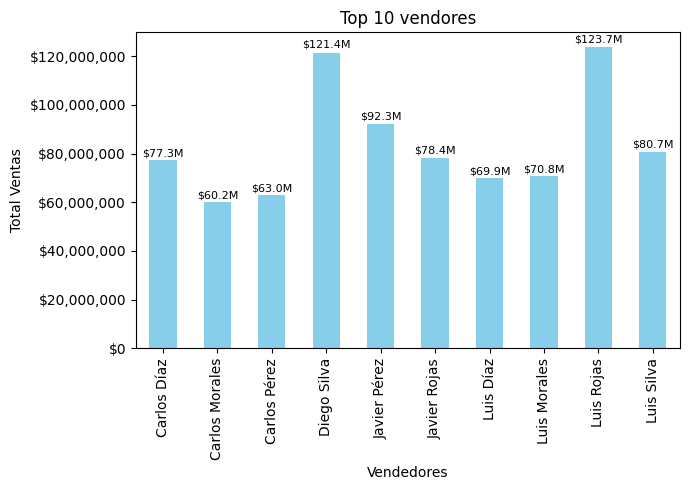

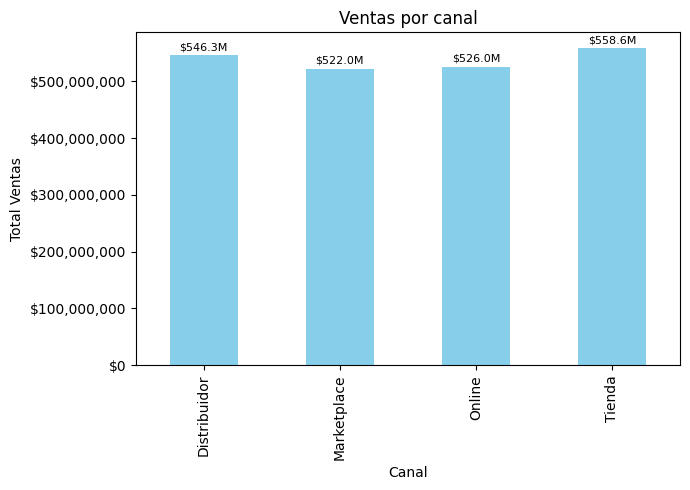

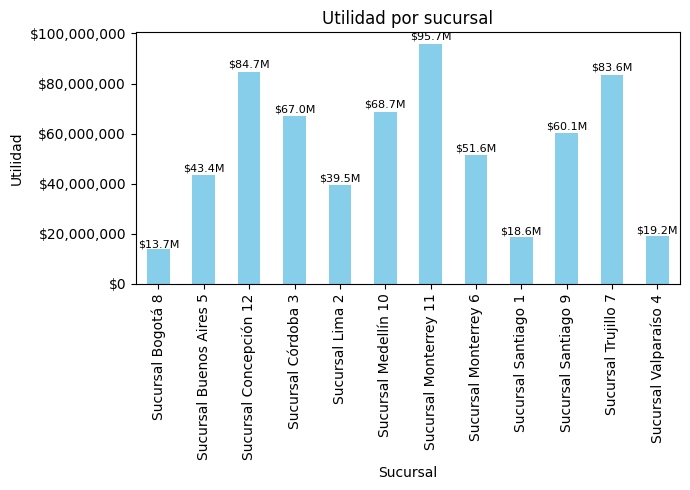

In [20]:
os.makedirs("Graficos", exist_ok=True)

# Grafico Ventas por mes
formato_moneda = FuncFormatter(lambda x, pos: f"${x:,.0f}")

Gra1 = Ventas_mes.plot(kind="bar", x="Periodo", y="Ventas_Netas", legend=False, color = "#87CEEB", figsize=(7,5))
Gra1.yaxis.set_major_formatter(formato_moneda)
for i, v in enumerate(Ventas_mes['Ventas_Netas']):    #for i, v in enumerate: recorre barra por barra la posicon y su valor de etiqueta, toma los datos de ventas_netas en la tabla ventas mes
  if v >= 1_000_000:
        etiqueta = f"${v / 1_000_000:.1f}M"
  elif v >= 1_000:
        etiqueta = f"${v / 1_000:.0f}K"
  else:
        etiqueta = f"${v:,.0f}"
  Gra1.text(i, v * 1.01, etiqueta, ha="center", va="bottom", fontsize=8)

plt.title("Ventas por mes")
plt.xlabel("Mes")
plt.ylabel("Total Ventas")
plt.tight_layout()
plt.savefig("/content/Graficos/Ventas_mes.png")
plt.show()

# Ventas_categoria
Gra2 = Ventas_categoria.plot(kind="bar", x="Categoria", y="Ventas_Netas", legend=False, color = "#87CEEB", figsize=(7,5))
Gra2.yaxis.set_major_formatter(formato_moneda)
for i, v in enumerate(Ventas_categoria['Ventas_Netas']):
  if v >= 1_000_000:
        etiqueta = f"${v / 1_000_000:.1f}M"
  elif v >= 1_000:
        etiqueta = f"${v / 1_000:.0f}K"
  else:
        etiqueta = f"${v:,.0f}"
  Gra2.text(i, v * 1.01, etiqueta, ha="center", va="bottom", fontsize=8)

plt.title("Ventas por categoria")
plt.xlabel("Categoria")
plt.ylabel("Total Ventas")
plt.tight_layout()
plt.savefig("/content/Graficos/Ventas_categoria.png")
plt.show()

# Top 10 productos
Gra3 = Top_productos.plot(kind="bar", x="Producto", y="Ventas_Netas", legend=False, color = "#87CEEB", figsize=(7,5))
Gra3.yaxis.set_major_formatter(formato_moneda)
for i, v in enumerate(Top_productos['Ventas_Netas']):
  if v >= 1_000_000:
        etiqueta = f"${v / 1_000_000:.1f}M"
  elif v >= 1_000:
        etiqueta = f"${v / 1_000:.0f}K"
  else:
        etiqueta = f"${v:,.0f}"
  Gra3.text(i, v * 1.01, etiqueta, ha="center", va="bottom", fontsize=8)

plt.title("Top 10 productos")
plt.xlabel("Productos")
plt.ylabel("Total Ventas")
plt.tight_layout()
plt.savefig("/content/Graficos/Top_productos.png")
plt.show()

# Top 10 vendedores
Gra4 = Top_vendedores.plot(kind="bar", x="Vendedor", y="Ventas_Netas", legend=False, color = "#87CEEB", figsize=(7,5))
Gra4.yaxis.set_major_formatter(formato_moneda)
for i, v in enumerate(Top_vendedores['Ventas_Netas']):
  if v >= 1_000_000:
        etiqueta = f"${v / 1_000_000:.1f}M"
  elif v >= 1_000:
        etiqueta = f"${v / 1_000:.0f}K"
  else:
        etiqueta = f"${v:,.0f}"
  Gra4.text(i, v * 1.01, etiqueta, ha="center", va="bottom", fontsize=8)

plt.title("Top 10 vendores")
plt.xlabel("Vendedores")
plt.ylabel("Total Ventas")
plt.tight_layout()
plt.savefig("/content/Graficos/Top_vendedores.png")
plt.show()

# Ventas por canal
Gra5 = Ventas_canal.plot(kind="bar", x="Canal", y="Ventas_Netas", legend=False, color = "#87CEEB", figsize=(7,5))
Gra5.yaxis.set_major_formatter(formato_moneda)
for i, v in enumerate(Ventas_canal['Ventas_Netas']):
  if v >= 1_000_000:
        etiqueta = f"${v / 1_000_000:.1f}M"
  elif v >= 1_000:
        etiqueta = f"${v / 1_000:.0f}K"
  else:
        etiqueta = f"${v:,.0f}"
  Gra5.text(i, v * 1.01, etiqueta, ha="center", va="bottom", fontsize=8)

plt.title("Ventas por canal")
plt.xlabel("Canal")
plt.ylabel("Total Ventas")
plt.tight_layout()
plt.savefig("/content/Graficos/Ventas_canal.png")
plt.show()

# Utilidad por sucursal
Gra6 = Utilidad_sucursal.plot(kind="bar", x="Sucursal", y="Utilidad", legend=False, color = "#87CEEB", figsize=(7,5))
Gra6.yaxis.set_major_formatter(formato_moneda)
for i, v in enumerate(Utilidad_sucursal['Utilidad']):
  if v >= 1_000_000:
        etiqueta = f"${v / 1_000_000:.1f}M"
  elif v >= 1_000:
        etiqueta = f"${v / 1_000:.0f}K"
  else:
        etiqueta = f"${v:,.0f}"
  Gra6.text(i, v * 1.01, etiqueta, ha="center", va="bottom", fontsize=8)

plt.title("Utilidad por sucursal")
plt.xlabel("Sucursal")
plt.ylabel("Utilidad")
plt.tight_layout()
plt.savefig("/content/Graficos/Utilidad_sucursal.png")
plt.show()

# Ventas reales Vs. Metas ventas
# Unidades reales Vs. Metas unidades

In [25]:
# Tabla_resumen_KPIs
kpis = pd.DataFrame({
    "KPI": [
        "Ventas Totales",
        "Utilidad Total",
        "Margen Promedio",
        "Cantidad Vendida",
        "Numero de Ventas",
        "Ticket Promedio",
        "Descuento Promedio"],

    "Valor": [
        Ventas_totales,
        Utilidad_total,
        Margen_promedio,
        Cantidad_vendida,
        Numero_ventas,
        Ticket_promedio,
        Descuento_promedio]})

with pd.ExcelWriter("reporte_final_analisis_comercial.xlsx",engine="openpyxl") as writer:
  Base_analitica_final.to_excel(writer, sheet_name="Base_Analitica",index=False)
  kpis.to_excel(writer, sheet_name="KPIs", index=False)
  Ventas_mes.to_excel(writer,sheet_name="Ventas_Mes",index=False)
  Ventas_categoria.to_excel(writer,sheet_name="Ventas_Categoria",index=False)
  Ventas_pais.to_excel(writer,sheet_name="Ventas_Pais",index=False)
  Ventas_canal.to_excel(writer,sheet_name="Ventas_Canal",index=False)
  Top_productos.to_excel(writer,sheet_name="Top_Productos",index=False)
  Top_vendedores.to_excel(writer,sheet_name="Top_Vendedores",index=False)
  Utilidad_sucursal.to_excel(writer,sheet_name="Utilidad_Sucursal",index=False)
  Cumplimiento_metas.to_excel(writer,sheet_name="Cumplimiento_Metas",index=False)

print("Reporte final exportado")

Reporte final exportado correctamente
